# WellSense · Notebook 4 — Evaluation
**Question:** how well does the knowledge-based system diagnose real Petrobras events it has never seen, and what does each design choice contribute?

| Section | Experiment |
|---|---|
| 1 | Evaluation protocol (development vs held-out instances) |
| 2 | **Held-out results**: accuracy, detection rate, false alarms, detection delay, confusion matrix |
| 3 | Error analysis by well |
| 4 | **Ablation study**: remove one KBS feature at a time |
| 5 | **Robustness to missing sensors** (incomplete information) |
| 6 | **Backward chaining** with a simulated operator |
| 7 | **Comparison with a machine-learning baseline** (Random Forest) — accuracy vs explainability |
| 8 | Summary |

**Requirements:** the held-out experiments need `db/wellsense_full.db` (run Notebook 0, then Notebook 1 with `USE_FULL_DATA = True`). If it is missing, the notebook loads the saved results from `outputs/tables/` so it can still be read and run.

## Setup

In [1]:
SOURCE = 'drive'          # 'drive' or 'upload' (see Notebook 1)
RERUN = True              # False = load saved results instead of recomputing (quicker)

import os, sys, zipfile
try:
    import google.colab
    IN_COLAB = True
except ImportError:
    IN_COLAB = False
if not IN_COLAB:
    PROJECT_DIR = os.getcwd()
elif SOURCE == 'drive':
    from google.colab import drive
    drive.mount('/content/drive')
    # Find the WellSense folder, even if it ended up one level deeper (e.g. MyDrive/WellSense/WellSense)
    import glob
    _cands = ['/content/drive/MyDrive/WellSense'] + sorted(glob.glob('/content/drive/MyDrive/WellSense*')) \
             + sorted(glob.glob('/content/drive/MyDrive/*/WellSense*'))
    _cands += [c + '/WellSense' for c in list(_cands)]
    _found = [c for c in _cands if os.path.isfile(os.path.join(c, 'wellsense', '__init__.py'))]
    if not _found:
        raise FileNotFoundError("WellSense folder not found in My Drive. Upload the WHOLE unzipped WellSense folder "
                                "(it must contain the folders 'wellsense', 'data' and 'knowledge_base') to My Drive.")
    PROJECT_DIR = _found[0]
    print('Project folder:', PROJECT_DIR)
else:
    from google.colab import files
    PROJECT_DIR = '/content/WellSense'
    if not os.path.exists(PROJECT_DIR):
        for name in files.upload():
            zipfile.ZipFile(name).extractall('/content')
os.chdir(PROJECT_DIR)
sys.path.insert(0, PROJECT_DIR)
os.makedirs('outputs/figures', exist_ok=True); os.makedirs('outputs/tables', exist_ok=True)

import sqlite3, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from wellsense import KnowledgeBase, InferenceEngine, evaluate, monitor

warnings.filterwarnings('ignore')
pd.set_option('display.width', 220); pd.set_option('display.max_colwidth', 90)
plt.rcParams.update({'figure.dpi': 100, 'axes.spines.top': False, 'axes.spines.right': False})

kb = KnowledgeBase('knowledge_base')
FAULTS = list(kb.faults); LABEL = {f: kb.faults[f]['label'] for f in FAULTS}
LABEL.update({'NORMAL': 'Normal', 'UNDETERMINED': 'Undetermined'})
FULL_DB, DEV_DB = 'db/wellsense_full.db', 'db/wellsense.db'
HAVE_FULL = os.path.exists(FULL_DB)
RUN = RERUN and HAVE_FULL
print('Full database available:', HAVE_FULL, '| recomputing:', RUN)
# Definitions: a "false alarm" / "detection" means a FAULT verdict; an Undetermined verdict is an abstention, not an alarm.

def saved(name):
    return pd.read_csv(f'outputs/tables/{name}.csv')

Full database available: True | recomputing: True


---
## 1. Evaluation protocol
* **Development set** — the 125 instances in the approved working file (Notebook 0). Used to build and *refine* the knowledge base and to choose the alarm settings (Notebook 3).
* **Held-out set** — the other **994 real instances**. Never looked at while building the KBS. Thresholds learned in the ETL are also taken from the development set, so nothing is learned from the test data.
* 35 held-out *hydrate in service line* instances have no abnormal label at all (Notebook 1, data finding) and are reported separately, leaving **959** scored instances.
* Instance-level decision (same as a control room): an **alarm** is raised when a fault's CF stays ≥ 0.6 for 5 minutes; the instance's diagnosis is the fault with the longest alarm, *Normal* if there is none, *Undetermined* if the KBS lacked trustworthy sensors most of the time.

**Important limitation of the split:** the development set took *all* instances of the four rarest faults (BSW 4, quick restriction 6, productivity loss 11, hydrate in production line 14). The held-out set therefore tests **6 of the 10 classes**; for the other four only development-set results exist (Notebook 3), which are optimistic because the rules were refined on them.

In [2]:
if HAVE_FULL:
    inst_full = pd.read_sql('SELECT * FROM instances', sqlite3.connect(FULL_DB)).set_index('instance_id')
    inst_full['labels_consistent'] = inst_full['labels_consistent'].astype(bool)
    dev_ids = set(pd.read_sql('SELECT instance_id FROM instances', sqlite3.connect(DEV_DB)).instance_id)
    held = [i for i in inst_full.index if i not in dev_ids]
    split = pd.DataFrame({
        'development': inst_full.loc[list(dev_ids)].groupby('event_name').size(),
        'held-out': inst_full.loc[held].groupby('event_name').size(),
        'held-out, label-consistent': inst_full.loc[held][inst_full.loc[held, 'labels_consistent']].groupby('event_name').size(),
    }).fillna(0).astype(int)
    split.to_csv('outputs/tables/eval_split.csv')
else:
    split = saved('eval_split').set_index('event_name')
split

,development,held-out,"held-out, label-consistent"
event_name,,,
ABRUPT_INCREASE_OF_BSW,4,0,0
FLOW_INSTABILITY,15,328,328
HYDRATE_IN_PRODUCTION_LINE,14,0,0
HYDRATE_IN_SERVICE_LINE,15,42,7
NORMAL,15,579,579
QUICK_RESTRICTION_IN_PCK,6,0,0
RAPID_PRODUCTIVITY_LOSS,11,0,0
SCALING_IN_PCK,15,21,21
SEVERE_SLUGGING,15,17,17


---
## 2. Held-out results

In [3]:
t0 = time.time()
if RUN:
    res = evaluate.run(InferenceEngine(kb, keep_trace=False), FULL_DB, held, inst_full, progress_every=200)
    res.to_csv('outputs/tables/heldout_results.csv', index=False)
else:
    res = saved('heldout_results')
print(f'({time.time() - t0:.0f}s)')
headline = evaluate.scores(res)
headline.round(3).to_frame('WellSense KBS — held-out')

  200/994 instances  (22s)
  400/994 instances  (42s)
  600/994 instances  (61s)
  800/994 instances  (84s)
(162s)


,WellSense KBS — held-out
instances,959.000
accuracy,0.521
balanced_accuracy,0.574
event_detection_rate,0.226
false_alarm_rate_normal_wells,0.157
alarm_during_labelled_normal_minutes,0.096
undetermined_rate,0.062
median_detection_delay_min,17.500


In [4]:
pc = evaluate.per_class(res)
pc.index = pc.index.map(LABEL)
pc.round(2)

,instances,recall,precision,detected_as_some_fault,median_delay_min
true,,,,,
Flow instability,328,0.12,0.79,0.15,17.0
Hydrate in service line,7,0.43,1.00,1.00,28.5
Normal,579,0.74,0.60,0.16,NaN
Scaling in PCK,21,0.33,0.64,0.33,1314.0
Severe slugging,17,0.82,0.61,1.00,15.0
Spurious closure of DHSV,7,1.00,1.00,1.00,7.0


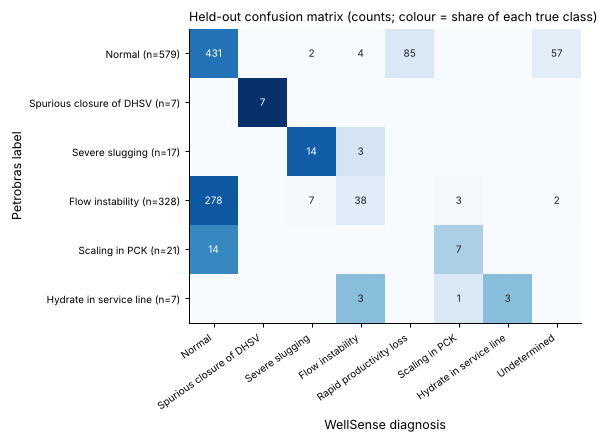

In [5]:
r = res[res.labels_consistent]
order = [c for c in ['NORMAL'] + FAULTS if c in set(r['true'])]
cols = [c for c in ['NORMAL'] + FAULTS + ['UNDETERMINED'] if c in set(r['predicted'])]
cm = pd.crosstab(r['true'], r['predicted']).reindex(index=order, columns=cols, fill_value=0)
cmn = cm.div(cm.sum(axis=1), axis=0)
fig, ax = plt.subplots(figsize=(10, 5))
im = ax.imshow(cmn.values, cmap='Blues', vmin=0, vmax=1)
ax.set_xticks(range(len(cols)), [LABEL[c] for c in cols], rotation=35, ha='right', fontsize=8)
ax.set_yticks(range(len(order)), [f'{LABEL[c]} (n={cm.loc[c].sum()})' for c in order], fontsize=8)
for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        if cm.values[i, j]:
            ax.text(j, i, cm.values[i, j], ha='center', va='center', fontsize=8, color='white' if cmn.values[i, j] > 0.55 else '#222')
ax.set_xlabel('WellSense diagnosis'); ax.set_ylabel('Petrobras label')
ax.set_title('Held-out confusion matrix (counts; colour = share of each true class)', loc='left', fontsize=10)
plt.tight_layout(); plt.savefig('outputs/figures/30_heldout_confusion.png', dpi=150); plt.show()

### Detection delay
Minutes from the labelled fault onset to WellSense's first alarm for the correct fault (negative = before Petrobras's label).

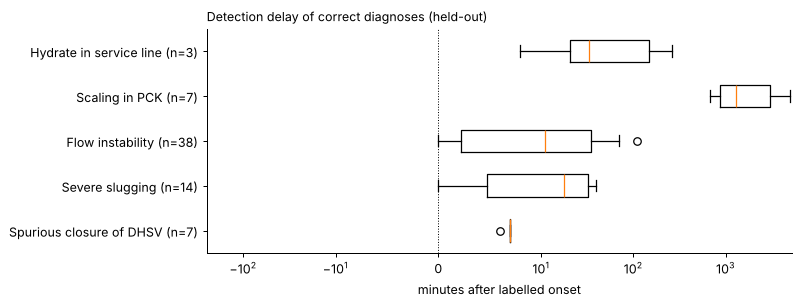

,count,min,50%,max
true,,,,
Flow instability,38.0,0.0,11.0,111.0
Hydrate in service line,3.0,8.0,33.0,260.0
Scaling in PCK,7.0,683.0,1314.0,5001.0
Severe slugging,14.0,0.0,18.0,40.0
Spurious closure of DHSV,7.0,6.0,7.0,7.0


In [6]:
d = r[r['correct'] & (r['true'] != 'NORMAL')].dropna(subset=['detection_delay_min'])
groups = [(LABEL[f], d.loc[d['true'] == f, 'detection_delay_min'].values) for f in FAULTS if (d['true'] == f).any()]
fig, ax = plt.subplots(figsize=(9, 3.5))
ax.boxplot([g for _, g in groups], vert=False)
ax.set_yticks(range(1, len(groups) + 1), [f'{n} (n={len(g)})' for n, g in groups])
ax.axvline(0, color='k', lw=0.8, ls=':')
ax.set_xlabel('minutes after labelled onset'); ax.set_xscale('symlog', linthresh=10)
ax.set_title('Detection delay of correct diagnoses (held-out)', loc='left', fontsize=10)
plt.tight_layout(); plt.savefig('outputs/figures/31_detection_delay.png', dpi=150); plt.show()
d.groupby('true')['detection_delay_min'].describe()[['count', 'min', '50%', 'max']].rename(index=LABEL)

---
## 3. Error analysis by well
Where do the errors come from?

In [7]:
n = r[r['true'] == 'NORMAL']
display(pd.crosstab(n['well_id'], n['predicted'].map(LABEL)).assign(instances=lambda t: t.sum(axis=1)))
fi = r[r['true'] == 'FLOW_INSTABILITY']
pd.crosstab(fi['well_id'], fi['predicted'].map(LABEL)).assign(instances=lambda t: t.sum(axis=1))

predicted,Flow instability,Normal,Rapid productivity loss,Severe slugging,Undetermined,instances
well_id,,,,,,
WELL-00001,4,86,1,0,0,91
WELL-00002,0,120,84,2,1,207
WELL-00003,0,24,0,0,0,24
WELL-00004,0,10,0,0,0,10
WELL-00005,0,79,0,0,0,79
WELL-00006,0,111,0,0,0,111
WELL-00007,0,1,0,0,0,1
WELL-00008,0,0,0,0,56,56


predicted,Flow instability,Normal,Scaling in PCK,Severe slugging,Undetermined,instances
well_id,,,,,,
WELL-00001,13,10,3,7,0,33
WELL-00002,0,108,0,0,2,110
WELL-00004,0,41,0,0,0,41
WELL-00005,0,36,0,0,0,36
WELL-00007,8,0,0,0,0,8
WELL-00010,0,81,0,0,0,81
WELL-00014,17,2,0,0,0,19


**Findings**
* Almost all false *rapid productivity loss* alarms on normal wells come from **one well (WELL-00002)**, whose normal operation includes slow pressure declines that look like a loss of reservoir energy. Excluding that well, false alarms on normal wells are rare. → Future work: learn each well's own normal behaviour instead of one set of thresholds for all wells.
* All *Undetermined* verdicts on normal wells come from **WELL-00008**, which has none of the key sensors — abstaining is the correct behaviour there.
* **Flow instability** is detected well on some wells and not at all on others: its tolerable, non-periodic swings are often within normal variation for the sensors available. This matches its description as *tolerable* (Vargas 2019) and is the main source of missed events.

In [8]:
excl = r[r['well_id'] != 'WELL-00002']
pd.Series({
    'false-alarm rate on normal wells (all)': (r.loc[r['true'] == 'NORMAL', 'predicted'].isin(FAULTS)).mean(),
    'false-alarm rate on normal wells (excluding WELL-00002)': (excl.loc[excl['true'] == 'NORMAL', 'predicted'].isin(FAULTS)).mean(),
    'accuracy excluding Undetermined verdicts': r.loc[r['predicted'] != 'UNDETERMINED', 'correct'].mean(),
}).round(3).to_frame('value')

,value
false-alarm rate on normal wells (all),0.157
false-alarm rate on normal wells (excluding WELL-00002),0.013
accuracy excluding Undetermined verdicts,0.556


---
## 4. Ablation study
Each variant removes one design feature and is run on the same held-out instances.

| Variant | What is removed |
|---|---|
| No data-quality weighting | Every available reading gets trust 1.0 (frozen readings are trusted fully) |
| No oscillation gate | Location rules also fire while the flow oscillates (`S-OSC-*` rules disabled) |
| No operation context | Meta-rules for shut-in / restart / intervention disabled (`M-OP-*`) |
| No sensor validation | Frozen/failed-sensor rules disabled (`V-*`) |

In [9]:
def variant(name, disable=(), **kw):
    disabled = [r.id for r in kb.rules if any(r.id.startswith(p) for p in disable)]
    return name, InferenceEngine(kb, keep_trace=False, disabled_rules=disabled, **kw)

variants = [variant('Full WellSense'),
            variant('No data-quality weighting', use_quality=False),
            variant('No oscillation gate', disable=['S-OSC-']),
            variant('No operation context', disable=['M-OP-']),
            variant('No sensor validation', disable=['V-'])]
if RUN:
    rows = []
    for name, eng in variants:
        rr = res if name == 'Full WellSense' else evaluate.run(eng, FULL_DB, held, inst_full, progress_every=0)
        rows.append(evaluate.scores(rr).rename(name))
        print('done:', name)
    ablation = pd.DataFrame(rows)
    ablation.to_csv('outputs/tables/ablation.csv')
else:
    ablation = saved('ablation').set_index('Unnamed: 0')
ablation[['accuracy', 'balanced_accuracy', 'event_detection_rate', 'false_alarm_rate_normal_wells', 'undetermined_rate']].round(3)

done: Full WellSense
done: No data-quality weighting
done: No oscillation gate
done: No operation context
done: No sensor validation


,accuracy,balanced_accuracy,event_detection_rate,false_alarm_rate_normal_wells,undetermined_rate
Full WellSense,0.521,0.574,0.226,0.157,0.062
No data-quality weighting,0.521,0.574,0.226,0.157,0.062
No oscillation gate,0.531,0.646,0.250,0.157,0.062
No operation context,0.521,0.574,0.226,0.157,0.062
No sensor validation,0.521,0.574,0.226,0.157,0.062


**Reading the ablation (honest result):**
* **No oscillation gate** scores *higher* on the held-out set (balanced accuracy 64.6 % vs 57.4 %). The gate was added because it helped on the development set, but it does not generalise — a textbook case of **over-fitting to a small development set**, and the reason a separate held-out test is essential. It is reported, not 'fixed', because changing the system after seeing test results would contaminate the test.
* **Data-quality weighting, operation context and sensor validation** do not change held-out accuracy. These features target situations that are rare in the held-out wells (operations occur almost only in hydrate events, all of which are in the development set) and they mainly serve **explanation and safety**: frozen sensors are flagged and discounted with a reason, and stopped flow during an operation is not misreported as a fault.

---
## 5. Robustness to missing sensors
To test how gracefully the KBS degrades, sensors are **deliberately removed**: for each instance, a random share of its key sensors is made unavailable (trust 0, all facts unknown) for the whole instance. Run on all held-out event instances plus 150 random normal instances; repeated for 0 %, 25 %, 50 % and 75 % removal (fixed random seed).

done: 0.0
done: 0.25
done: 0.5
done: 0.75


,sensors removed,accuracy,event_detection_rate,false_alarm_rate_normal_wells,undetermined_rate
0,0%,0.358,0.226,0.127,0.023
1,25%,0.328,0.142,0.053,0.055
2,50%,0.189,0.071,0.007,0.481
3,75%,0.140,0.024,0.000,0.617


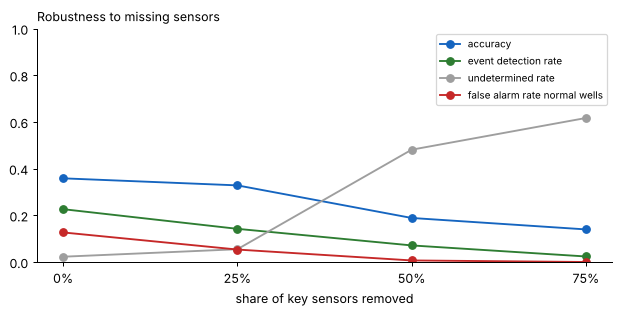

In [10]:
KEY = kb.settings['key_sensors']
KINDS = ('level', 'trend', 'osc', 'step', 'cycle', 'jump30', 'drift')

def drop_sensors(share, seed):
    rng = np.random.default_rng(seed)
    def transform(g):
        present = [v for v in KEY if (g[f'{v}_rel'] > 0).any()]
        k = int(round(share * len(present)))
        for v in rng.choice(present, size=k, replace=False) if k else []:
            g[f'{v}_rel'] = 0.0
            for kind in KINDS:
                if f'{v}_{kind}' in g:
                    g[f'{v}_{kind}'] = 'UNKNOWN'
            g[f'{v}_q'] = 'GAP'
        return g
    return transform

if RUN:
    hr = res.set_index('instance_id')
    rng = np.random.default_rng(0)
    normals = [i for i in held if hr.loc[i, 'true'] == 'NORMAL' and hr.loc[i, 'labels_consistent']]
    sample = [i for i in held if hr.loc[i, 'true'] != 'NORMAL' and hr.loc[i, 'labels_consistent']] + list(rng.choice(normals, 150, replace=False))
    eng = InferenceEngine(kb, keep_trace=False)
    rows = []
    for share in [0.0, 0.25, 0.5, 0.75]:
        rr = evaluate.run(eng, FULL_DB, sample, inst_full, progress_every=0, transform=drop_sensors(share, seed=1))
        s = evaluate.scores(rr)
        rows.append({'sensors removed': f'{share:.0%}', 'accuracy': s['accuracy'], 'event_detection_rate': s['event_detection_rate'],
                     'false_alarm_rate_normal_wells': s['false_alarm_rate_normal_wells'], 'undetermined_rate': s['undetermined_rate']})
        print('done:', share)
    robust = pd.DataFrame(rows)
    robust.to_csv('outputs/tables/robustness.csv', index=False)
else:
    robust = saved('robustness')
display(robust.round(3))
fig, ax = plt.subplots(figsize=(7, 3.6))
for c, col in [('accuracy', '#1565c0'), ('event_detection_rate', '#2e7d32'), ('undetermined_rate', '#9e9e9e'),
               ('false_alarm_rate_normal_wells', '#c62828')]:
    ax.plot(robust['sensors removed'], robust[c], marker='o', color=col, label=c.replace('_', ' '))
ax.set_ylim(0, 1); ax.legend(fontsize=8); ax.set_xlabel('share of key sensors removed')
ax.set_title('Robustness to missing sensors', loc='left', fontsize=10)
plt.tight_layout(); plt.savefig('outputs/figures/32_robustness.png', dpi=150); plt.show()

As sensors are removed, false alarms on normal wells fall to zero and the share of **Undetermined** verdicts rises (to 62 % at 75 % removal): the KBS abstains instead of guessing. Correct detections fall too — with three-quarters of the key sensors gone, most faults simply cannot be seen.

As sensors disappear, the KBS does not start guessing: detection falls gradually and more instances become **Undetermined** instead of being silently called normal.

---
## 6. Backward chaining with a simulated operator
Forward chaining uses only sensors. When the KBS is unsure (0.3 ≤ CF < 0.8) it can **ask** a person. To measure what this adds, each question is answered by a **simulated operator** who knows the true situation (e.g. *"Does a fluid sample show more water?"* → YES only when the true fault is a BSW increase). This is an **upper bound**: real answers can be wrong or unavailable.

For every instance, the KBS is consulted at the first moment it becomes suspicious (some fault CF ≥ 0.3 for 5 minutes after the fault onset, or anywhere in a normal instance). We compare the verdict **before** and **after** the questions, on the development set (all 10 classes) and the held-out set.

In [11]:
def oracle(true_fault):
    yes = {'Q_DHSV_COMMANDED': False, 'Q_DHSV_HYDRAULICS': True,
           'Q_WATER_SAMPLE': true_fault == 'ABRUPT_INCREASE_OF_BSW',
           'Q_SEPARATOR_SURGES': true_fault == 'SEVERE_SLUGGING',
           'Q_SETPOINT_CHANGE': False,
           'Q_WELL_TEST': true_fault in ('RAPID_PRODUCTIVITY_LOSS', 'ABRUPT_INCREASE_OF_BSW'),
           'Q_CHOKE_LOCAL': true_fault == 'QUICK_RESTRICTION_IN_PCK',
           'Q_SCALE_HISTORY': true_fault == 'SCALING_IN_PCK',
           'Q_HYDRATE_CURVE': true_fault in ('HYDRATE_IN_PRODUCTION_LINE', 'HYDRATE_IN_SERVICE_LINE'),
           'Q_RECENT_RESTART': true_fault == 'HYDRATE_IN_PRODUCTION_LINE',
           'Q_SERVICE_LINE_INHIBITOR': true_fault == 'HYDRATE_IN_SERVICE_LINE'}
    return lambda q, why: 'YES' if yes.get(q['id']) else 'NO'

def consult_eval(db, ids, inst):
    eng = InferenceEngine(kb, keep_trace=False)
    out = []
    con = sqlite3.connect(db)
    for iid in ids:
        meta = inst.loc[iid]
        if not meta['labels_consistent']:
            continue
        g = evaluate.load_instance(con, iid)
        tl = monitor.replay(eng, g)
        top = tl[FAULTS].max(axis=1)
        start = meta['onset_minute'] if pd.notna(meta['onset_minute']) else 0
        sus = ((top >= kb.settings['ask_threshold']) & (tl['minute'] >= start)).astype(int)
        run = sus.groupby((sus == 0).cumsum()).cumsum()
        hit = tl.loc[run >= 5, 'minute']
        if hit.empty:
            continue
        m = int(hit.iloc[0])
        wm = eng.forward_chain(eng.initial_memory(g.iloc[m].to_dict(), monitor.ANALOG))
        before = eng.verdict(wm)[0]
        eng.consult(wm, oracle(meta['event_name']))
        out.append({'instance_id': iid, 'true': meta['event_name'], 'before': before, 'after': eng.verdict(wm)[0],
                    'questions': len(wm.asked)})
    return pd.DataFrame(out)

if RUN:
    inst_dev = pd.read_sql('SELECT * FROM instances', sqlite3.connect(DEV_DB)).set_index('instance_id')
    inst_dev['labels_consistent'] = inst_dev['labels_consistent'].astype(bool)
    bc = pd.concat([consult_eval(DEV_DB, list(inst_dev.index), inst_dev).assign(set='development'),
                    consult_eval(FULL_DB, held, inst_full).assign(set='held-out')])
    bc.to_csv('outputs/tables/backward_chaining.csv', index=False)
else:
    bc = saved('backward_chaining')
bc['correct before'] = bc['true'] == bc['before']
bc['correct after'] = bc['true'] == bc['after']
bc.groupby('set').agg(suspicious_instances=('true', 'size'), questions_asked=('questions', 'mean'),
                      accuracy_before=('correct before', 'mean'), accuracy_after=('correct after', 'mean')).round(3)

,suspicious_instances,questions_asked,accuracy_before,accuracy_after
set,,,,
development,79,1.519,0.278,0.430
held-out,286,1.479,0.479,0.483


In [12]:
bc[bc['set'] == 'development'].groupby('true').agg(n=('true', 'size'), before=('correct before', 'mean'),
                                                  after=('correct after', 'mean')).rename(index=LABEL).round(2)

,n,before,after
true,,,
Abrupt increase of BSW,3,0.00,0.00
Flow instability,9,0.33,0.33
Hydrate in production line,13,0.00,0.31
Hydrate in service line,6,0.17,0.83
Normal,1,1.00,1.00
Quick restriction in PCK,4,0.00,0.00
Rapid productivity loss,11,0.09,0.09
Scaling in PCK,2,1.00,1.00
Severe slugging,15,0.47,0.47


---
## 7. Comparison with a machine-learning baseline
A **Random Forest** (scikit-learn, 200 trees) is trained on the same development minutes, using the numeric features from the ETL (deviation from baseline, 15-min change, 30-min variability, 1-min change and 3-hour drift for each sensor; missing values filled with 0 plus a missing-indicator per sensor). It then makes per-minute predictions on the held-out instances, and **the same alarm logic** (probability ≥ 0.6 for 5 minutes, longest alarm) turns them into instance diagnoses.

In [13]:
from sklearn.ensemble import RandomForestClassifier

FEAT_SUFFIX = ('_dev', '_d15', '_std30', '_d1', '_d180')

def feature_matrix(db, ids=None):
    con = sqlite3.connect(db)
    f = pd.read_sql('SELECT * FROM features', con)
    meta = pd.read_sql('SELECT instance_id, timestamp, phase, event_name FROM facts', con)
    f = f.merge(meta, on=['instance_id', 'timestamp'])
    if ids is not None:
        f = f[f['instance_id'].isin(ids)]
    cols = [c for c in f.columns if c.endswith(FEAT_SUFFIX)]
    X = f[cols].copy()
    for v in sorted({c.rsplit('_', 1)[0] for c in cols}):
        X[f'{v}_missing'] = f[f'{v}_dev'].isna().astype(int)
    X = X.fillna(0.0)
    y = np.where(f['phase'].isin(['transient', 'steady']), f['event_name'], np.where(f['phase'] == 'normal', 'NORMAL', None))
    return f[['instance_id', 'timestamp']], X, y

if RUN:
    ids_dev, Xd, yd = feature_matrix(DEV_DB)
    keep = yd != None
    rf = RandomForestClassifier(n_estimators=200, min_samples_leaf=5, class_weight='balanced', n_jobs=-1, random_state=0)
    rf.fit(Xd[keep], yd[keep])
    ids_h, Xh, _ = feature_matrix(FULL_DB, set(held))
    proba = pd.DataFrame(rf.predict_proba(Xh), columns=rf.classes_)
    proba['instance_id'] = ids_h['instance_id'].values
    rows = []
    for iid, p in proba.groupby('instance_id', sort=False):
        tl = p.reset_index(drop=True).assign(minute=lambda t: np.arange(len(t)), phase=None, insufficient_data=False)
        for f in FAULTS:
            if f not in tl:
                tl[f] = 0.0
        al = monitor.alarms(tl, FAULTS, 0.6, 5)
        meta = inst_full.loc[iid]
        out = monitor.summarise_instance(tl, al, None, FAULTS)
        rows.append({'instance_id': iid, 'true': meta['event_name'], 'predicted': out['predicted'],
                     'labels_consistent': bool(meta['labels_consistent']), 'alarm_before_onset': False,
                     'detection_delay_min': np.nan, 'well_id': meta['well_id']})
    ml = pd.DataFrame(rows); ml['correct'] = ml['true'] == ml['predicted']
    ml.to_csv('outputs/tables/ml_baseline_results.csv', index=False)
    imp = pd.Series(rf.feature_importances_, index=Xd.columns).sort_values(ascending=False).head(10)
    imp.to_csv('outputs/tables/ml_feature_importance.csv')
else:
    ml = saved('ml_baseline_results')
    imp = saved('ml_feature_importance').set_index('Unnamed: 0').iloc[:, 0]

majority = res.assign(predicted='NORMAL', correct=lambda t: t['true'] == 'NORMAL')
cmp = pd.DataFrame({'WellSense KBS': evaluate.scores(res), 'Random Forest (ML)': evaluate.scores(ml),
                    'Always "normal"': evaluate.scores(majority)}).T
cmp = cmp[['accuracy', 'balanced_accuracy', 'event_detection_rate', 'false_alarm_rate_normal_wells']]
cmp.to_csv('outputs/tables/kbs_vs_ml.csv')
cmp.round(3)

,accuracy,balanced_accuracy,event_detection_rate,false_alarm_rate_normal_wells
WellSense KBS,0.521,0.574,0.226,0.157
Random Forest (ML),0.754,0.770,0.689,0.181
"Always ""normal""",0.604,0.167,0.000,0.000


**Result:** the Random Forest is clearly more accurate (75 % vs 52 %), mainly on flow instability and scaling, whose subtle patterns are easier to learn from examples than to write as rules. WellSense gives **fewer false alarms on normal wells** (15.7 % vs 18.1 %), equals it on DHSV closures and is better on hydrate in the service line. The comparison below explains why accuracy alone does not decide the choice.

In [14]:
pml = evaluate.per_class(ml)[['recall']].rename(columns={'recall': 'Random Forest recall'})
pk = evaluate.per_class(res)[['instances', 'recall']].rename(columns={'recall': 'WellSense recall'})
pk.join(pml).rename(index=LABEL).round(2)

,instances,WellSense recall,Random Forest recall
true,,,
Flow instability,328,0.12,0.62
Hydrate in service line,7,0.43,0.29
Normal,579,0.74,0.82
Scaling in PCK,21,0.33,0.95
Severe slugging,17,0.82,0.94
Spurious closure of DHSV,7,1.00,1.00


**The Random Forest's explanation is only this** — which inputs mattered on average, not why a particular well was diagnosed:

In [15]:
imp.round(3).to_frame('importance')

,importance
p_tpt_dev,0.059
p_tpt_std30,0.055
t_tpt_std30,0.052
t_tpt_dev,0.051
p_jus_ckgl_std30,0.046
p_tpt_d180,0.043
p_mon_ckp_std30,0.038
t_jus_ckp_std30,0.036
p_anular_dev,0.036
qgl_std30,0.035


| Requirement from the brief | WellSense KBS | Random Forest |
|---|---|---|
| Explain each diagnosis | Full HOW / WHY / WHY-NOT / WHAT-IF chain down to sensor readings, with literature sources | Global feature importance only |
| Incomplete information | Reasons with what is available; says *Undetermined*; asks the operator | Needs every input; missing values must be filled with an arbitrary number |
| Conflicting evidence | Detects frozen / failed sensors and discounts them, explaining why | Not detected |
| Safety | Hard safety constraints; unsafe actions blocked | No notion of safety |
| Maintenance recommendation | Ranked, stakeholder-aware, situation-aware | None |
| New fault or new knowledge | Add a rule and its source; no training data needed | Needs labelled examples of the new fault |
| Training data | 125 instances only used to *check and refine* expert rules | Learns everything from labelled data |

This trade-off between accuracy and explainability is the central argument of the report: see Section 8.

---
## 8. Summary

In [16]:
summary = pd.DataFrame({
    'held-out instances scored': [int(headline['instances'])],
    'accuracy': [headline['accuracy']], 'balanced accuracy': [headline['balanced_accuracy']],
    'event detection rate': [headline['event_detection_rate']],
    'false-alarm rate (normal wells)': [headline['false_alarm_rate_normal_wells']],
    'median detection delay (min)': [headline['median_detection_delay_min']],
}, index=['WellSense']).T
summary.to_csv('outputs/tables/summary.csv')
summary.round(3)

,WellSense
held-out instances scored,959.000
accuracy,0.521
balanced accuracy,0.574
event detection rate,0.226
false-alarm rate (normal wells),0.157
median detection delay (min),17.500
